## Assignment 3: $k$ Nearest Neighbor


**Q1.**
1. What is the difference between regression and classification?
2. What is a confusion table? What does it help us understand about a model's performance?
3. What does the SSE quantify about a particular model?
4. What are overfitting and underfitting? 
5. Why does splitting the data into training and testing sets, and choosing $k$ by evaluating accuracy or SSE on the test set, improve model performance?
6. With classification, we can report a class label as a prediction or a probability distribution over class labels. Please explain the strengths and weaknesses of each approach.

**Q2.** This is a case study on $k$ nearest neighbor classification, using the `land_mines.csv` data.

The data consists of a label, `mine_type`, taking integer values 1 to 5, and three properties of the mine, `voltage`, `height` and `soil`. We want to predict the kind of mine from data about it. Imagine working for the DOD or a humanitarian aid agency, trying to help people remove land mines more safely.

1. Load the data. Perform some EDA, summarizing the target label and the features.
2. Split the sample 50/50 into training and test/validation sets. (The smaller the data are, the more equal the split should be, in my experience: Otherwise, all of the members of one class end up in the training or test data, and the model falls apart.)
3. Build a $k$-NN classifier. Explain how you select $k$.
4. Print a confusion table for the optimal model, comparing predicted and actual class label on the test set. How accurate is it? Where is performance more or less accurate?
5. Notice that you can have a lot of accurate predictions for a given type of mine, but still make a lot of mistakes. Please explain how you'd advise someone to actually use this predictive model in practice, given the errors that it tends to make.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Araceli Soto
**Date:** 10/02/2026

    voltage    height  soil  mine_type
0  0.338157  0.000000   0.0          1
1  0.320241  0.181818   0.0          1
2  0.287009  0.272727   0.0          1
3  0.256284  0.454545   0.0          1
4  0.262840  0.545455   0.0          1
<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   voltage    338 non-null    float64
 1   height     338 non-null    float64
 2   soil       338 non-null    float64
 3   mine_type  338 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 10.7 KB
None
          voltage      height        soil
count  338.000000  338.000000  338.000000
mean     0.430634    0.508876    0.503550
std      0.195819    0.306043    0.344244
min      0.197734    0.000000    0.000000
25%      0.309737    0.272727    0.200000
50%      0.359516    0.545455    0.600000
75%      0.482628    0.727273    0.800000
max      0.999999    1.000000    1.000000

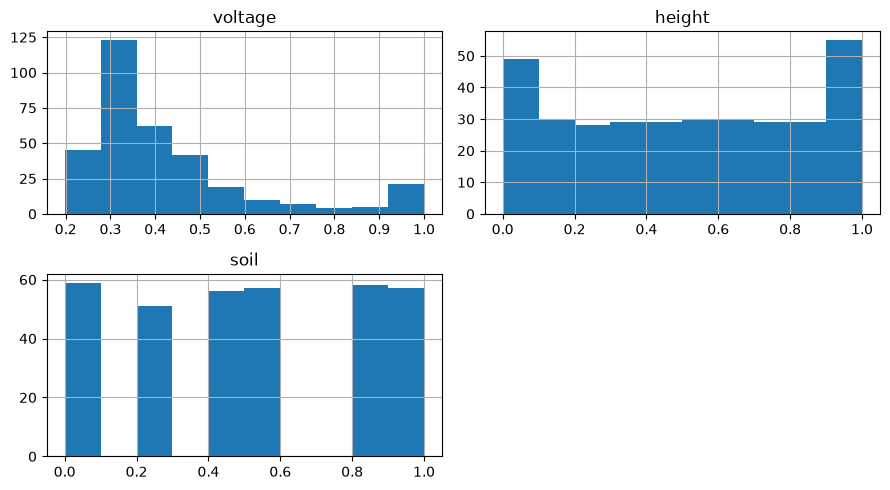

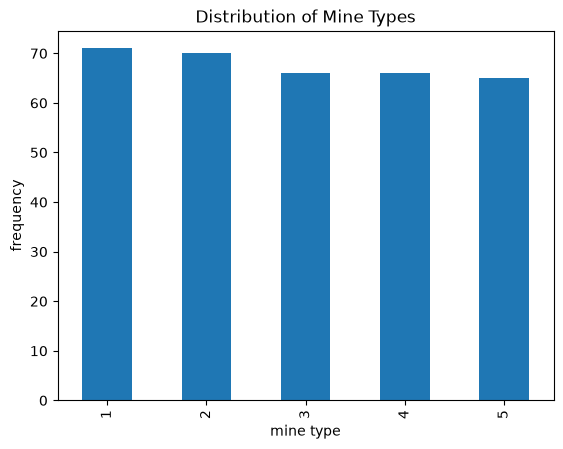

Training set size:
mine_type
1    37
2    32
3    36
4    28
5    36
Name: count, dtype: int64
Test set size:
mine_type
1    34
2    38
3    30
4    38
5    29
Name: count, dtype: int64
Best k: 2
Best accuracy: 0.44970414201183434
          Predicted 1  Predicted 2  Predicted 3  Predicted 4  Predicted 5
Actual 1           21            1            6            4            2
Actual 2            0           33            2            3            0
Actual 3            5            5           10            6            4
Actual 4           13            5           10            9            1
Actual 5           10            1            8            7            3
Final accuracy: 0.44970414201183434


In [ ]:
# Your Phase 1 solution to the problem goes here.
#1. The difference between regression and classification is that regression predicts numeric outcomes; meanwhile, classification predicts categories.
#  Moreover, regression can only find the predictions with the nearest neighbors for prediction; however, classification can estimate proportions by dividing k.
#2.The confusion table helps us understand predictions by comparing actual class and predicted class. 
# It helps us understand how many observations the model classified correctly and also identify classses.
#  Overall, helping us understand more information about the model's performance through predictions or identifying missclassifications.
#3. SSE measures the total squared prediction error of a reggresion model which when is a smaller value indicates a better fit or smaller errors.
#4. overfitting means that the model fits the training data too well which can lead to poor performance on new data. 
# Underfitting means that the model is too simple and cannot capture the underlying patterns in the data, leading to poor performance on both training and new data.
#5. splitting the data helps us test the model on data that we have not seen before, giving us a better idea of how well the model generalizes to the new data.
#6. class label gives us one clear prediction that is simple to understand, while probability gives us a more nuanced view of the model's confidence in its predictions.

#------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
data = pd.read_csv("land_mines.csv")
print(data.head())
print(data.info())

labels = data[["voltage", "height", "soil"]].describe()
print(labels)
print(data["mine_type"].value_counts().sort_index())
print(data.isna().sum())
data[["voltage", "height", "soil"]].hist(figsize=(9, 5))
plt.tight_layout()
plt.show()

data["mine_type"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("mine type")
plt.ylabel("frequency")
plt.title("Distribution of Mine Types")
plt.show()


from sklearn.model_selection import train_test_split
x = data[["voltage", "height", "soil"]]
y = data["mine_type"]
x_train, x_valid, y_train, y_valid = train_test_split(
    x,
    y,
    test_size=0.5,
    random_state=65
)
print("Training set size:")
print(y_train.value_counts().sort_index())
print("Test set size:")
print(y_valid.value_counts().sort_index())

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_valid_scaled = scaler.transform(x_valid)


results = []
# i selected the k based on the size of the training set, which is 50% of the original dataset. 
# I will test k values from 1 to the size of the training set. the selected value was k=2 meaning that the model uses the 2 nearest neighbors to make predictions.
for k in range(1, len(x_train) + 1):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_scaled, y_train)
    predictions = model.predict(x_valid_scaled)
    accuracy = np.mean(predictions == y_valid)
    results.append((k, accuracy))
results_df = pd.DataFrame(
    results,
    columns=["k", "accuracy"])

best_k = results_df.loc[
    results_df["accuracy"].idxmax(),
    "k"]

print("Best k:", best_k)
print(
    "Best accuracy:",
    results_df["accuracy"].max())
model = KNeighborsClassifier(
    n_neighbors=int(best_k))
model.fit(x_train_scaled, y_train)
predictions = model.predict(x_valid_scaled)

#the confusion table shows that the model is able to predict that mine type 2 had the strongest accuracy.
#my model is 44% accuracy in which the performance is less accurate in preditcting mine type 1 and mine type 5.

confusionmatrix = confusion_matrix(
    y_valid,
    predictions,
    labels=[1, 2, 3, 4, 5])

confusion_table = pd.DataFrame(
    confusionmatrix,
    index=[
        "Actual 1",
        "Actual 2",
        "Actual 3",
        "Actual 4",
        "Actual 5"
    ],
    columns=[
        "Predicted 1",
        "Predicted 2",
        "Predicted 3",
        "Predicted 4",
        "Predicted 5"
    ])

print(confusion_table)


accuracy = np.mean(predictions == y_valid)
print("Final accuracy:", accuracy)
# i would advise someone to use the model as an additional tool to help identify mine types, but not to rely solely on it. 
# The model's accuracy is not high enough to be the only method of identification, and it may misclassify some mine types. 


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 03d7b6120f0ad293fb3fefaaef1b7d45621c51d1
- **AI tool and model used:** Chat GPT 5.6 Luna

### *Prompts used

1. This is my code and assignment what are some ways I can improve or fix my work?
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. . Fix the written answers first
Q1 — Regression vs. classification

Your answer is basically correct, but this sentence is confusing:

“regression can only find the predictions with the nearest neighbors for prediction”
#1. The difference between regression and classification is that regression
#predicts numeric outcomes, while classification predicts categories or class labels.
#Regression can predict values on a continuous scale, while classification
#predicts which category an observation belongs to.

2. Your answer is good, but I would make it more specific. A confusion table doesn't just show whether the model is correct; it shows which classes are being confused with which other classes.

You could change it to:
#2. A confusion table compares the actual class labels with the predicted class labels.
#It helps us understand how many observations the model classified correctly and
#how many were misclassified. It also shows which classes the model tends to
#confuse with one another, giving us more information about the model's pe

3. Labels is a little misleading because those are your features, not labels.
 One tiny improvement: instead of calling this:
labels = data[["voltage", "height", "soil"]].describe()
I'd call it something like:
features_summary = data[["voltage", "height", "soil"]].describe()
print(features_summary)

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / REJECT | I think it helps me clarify the difference between terms but I don't i should change word by word but rather explain in my own words |
| 2 | Accept / modify / REJECT | I think it also helps but it also can be rephrased better on my own words by highliting other additional things that the confusion tables helps out with such as understanding how which classes can be confused with other classes.|
| 3 | ACCEPT / modify / reject | I think it would help me not get confused with my code.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
#1. The difference between regression and classification is that regression predicts numeric outcomes; meanwhile, classification predicts categories.
#  Moreover, regression can only find the predictions with the nearest neighbors for prediction; however, classification can estimate proportions by dividing k.
#2.The confusion table helps us understand predictions by comparing actual class and predicted class. 
# It helps us understand how many observations the model classified correctly and also identify classses.
#  Overall, helping us understand more information about the model's performance through predictions or identifying missclassifications.
#3. SSE measures the total squared prediction error of a reggresion model which when is a smaller value indicates a better fit or smaller errors.
#4. overfitting means that the model fits the training data too well which can lead to poor performance on new data. 
# Underfitting means that the model is too simple and cannot capture the underlying patterns in the data, leading to poor performance on both training and new data.
#5. splitting the data helps us test the model on data that we have not seen before, giving us a better idea of how well the model generalizes to the new data.
#6. class label gives us one clear prediction that is simple to understand, while probability gives us a more nuanced view of the model's confidence in its predictions.

#------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
data = pd.read_csv("land_mines.csv")
print(data.head())
print(data.info())

features_summary = data[["voltage", "height", "soil"]].describe()
print(features_summary)
print(data["mine_type"].value_counts().sort_index())
print(data.isna().sum())
data[["voltage", "height", "soil"]].hist(figsize=(9, 5))
plt.tight_layout()
plt.show()

data["mine_type"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("mine type")
plt.ylabel("frequency")
plt.title("Distribution of Mine Types")
plt.show()


from sklearn.model_selection import train_test_split
x = data[["voltage", "height", "soil"]]
y = data["mine_type"]
x_train, x_valid, y_train, y_valid = train_test_split(
    x,
    y,
    test_size=0.5,
    random_state=65
)
print("Training set size:")
print(y_train.value_counts().sort_index())
print("Test set size:")
print(y_valid.value_counts().sort_index())

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_valid_scaled = scaler.transform(x_valid)


results = []
# i selected the k based on the size of the training set, which is 50% of the original dataset. 
# I will test k values from 1 to the size of the training set. the selected value was k=2 meaning that the model uses the 2 nearest neighbors to make predictions.
for k in range(1, len(x_train) + 1):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_scaled, y_train)
    predictions = model.predict(x_valid_scaled)
    accuracy = np.mean(predictions == y_valid)
    results.append((k, accuracy))
results_df = pd.DataFrame(
    results,
    columns=["k", "accuracy"])

best_k = results_df.loc[
    results_df["accuracy"].idxmax(),
    "k"]

print("Best k:", best_k)
print(
    "Best accuracy:",
    results_df["accuracy"].max())
model = KNeighborsClassifier(
    n_neighbors=int(best_k))
model.fit(x_train_scaled, y_train)
predictions = model.predict(x_valid_scaled)

#the confusion table shows that the model is able to predict that mine type 2 had the strongest accuracy.
#my model is 44% accuracy in which the performance is less accurate in preditcting mine type 1 and mine type 5.

confusionmatrix = confusion_matrix(
    y_valid,
    predictions,
    labels=[1, 2, 3, 4, 5])

confusion_table = pd.DataFrame(
    confusionmatrix,
    index=[
        "Actual 1",
        "Actual 2",
        "Actual 3",
        "Actual 4",
        "Actual 5"
    ],
    columns=[
        "Predicted 1",
        "Predicted 2",
        "Predicted 3",
        "Predicted 4",
        "Predicted 5"
    ])

print(confusion_table)


accuracy = np.mean(predictions == y_valid)
print("Final accuracy:", accuracy)
# i would advise someone to use the model as an additional tool to help identify mine types, but not to rely solely on it. 
# The model's accuracy is not high enough to be the only method of identification, and it may misclassify some mine types. 


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

In [ ]:
#AI has helped me understand the concepts from different perspectives, such as understanding that regression isn't limited to the nearest neighbors for prediction, but can also estimate proportions by dividing k. It has also helped me understand the importance of the confusion table in understanding the model's performance and identifying misclassifications, but also going beyond that and understanding that the table can show which classes can be confused with other classes.

#Overall, AI helped me better understand how the model works and how to look beyond just the accuracy of the model. I also learned that a model does not have to be fully accurate to still be useful, as long as we understand where it makes mistakes and use those results appropriately.
#This helped me see that accuracy is not always the only important factor when evaluating a model, especially when some types of predictions are more difficult than others.